In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [27]:
# Carga de datos
PATH = "C:/Users/gonzalo/OneDrive - UVa/UVa/Master/1er BIMESTRE/Clas/proyecto/train.csv"
df = pd.read_csv(PATH)
sns.set_theme(style="whitegrid")

1. ATRIBUTOS CATEGÓRICOS / DISCRETOS

--- Distribución de vendor_id ---
|   Valor |   Frecuencia |   Porcentaje (%) |
|--------:|-------------:|-----------------:|
|       1 |       678342 |           46.505 |
|       2 |       780302 |           53.495 |




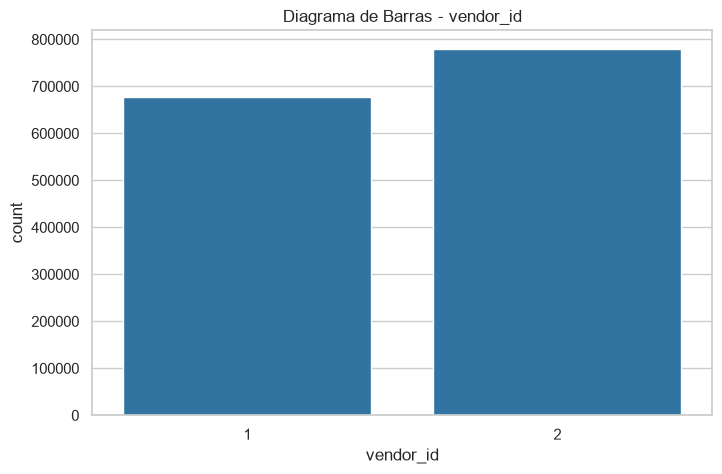

--- Distribución de passenger_count ---
|   Valor |       Frecuencia |   Porcentaje (%) |
|--------:|-----------------:|-----------------:|
|       0 |     60           |      0.00411341  |
|       1 |      1.03354e+06 |     70.8562      |
|       2 | 210318           |     14.4187      |
|       3 |  59896           |      4.10628     |
|       4 |  28404           |      1.94729     |
|       5 |  78088           |      5.35347     |
|       6 |  48333           |      3.31356     |
|       7 |      3           |      0.00020567  |
|       8 |      1           |      6.85568e-05 |
|       9 |      1           |      6.85568e-05 |




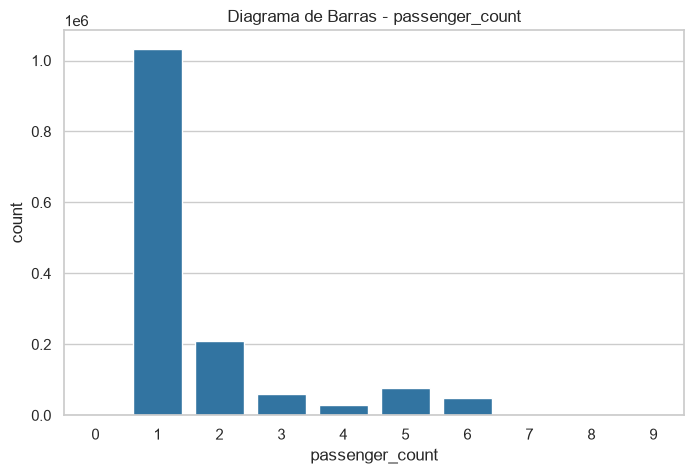

--- Distribución de store_and_fwd_flag ---
| Valor   |   Frecuencia |   Porcentaje (%) |
|:--------|-------------:|-----------------:|
| N       |      1450599 |         99.4485  |
| Y       |         8045 |          0.55154 |




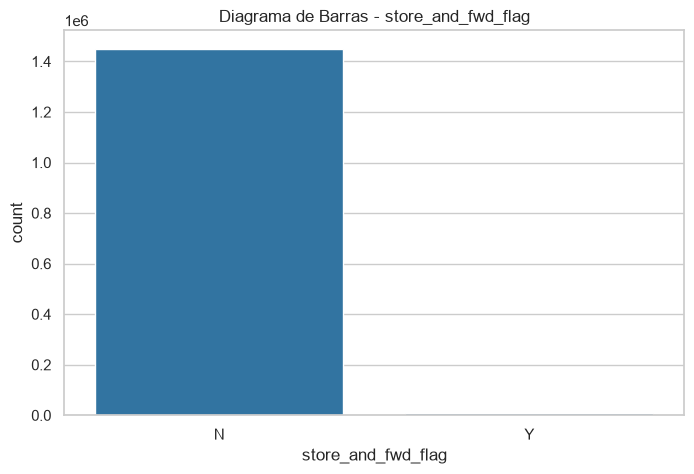

In [28]:
# Definición de atributos a analizar
categorical_cols = ['vendor_id', 'passenger_count', 'store_and_fwd_flag']
numeric_cols = ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'trip_duration']
temporal_cols = ['pickup_datetime', 'dropoff_datetime']

print("==========================================================")
print("1. ATRIBUTOS CATEGÓRICOS / DISCRETOS")
print("==========================================================\n")

for col in categorical_cols:
    # --- Cálculo de distribución completa (incluyendo 0s, nulos, etc.) ---
    dist = df[col].value_counts(dropna=False).reset_index()
    dist.columns = ['Valor', 'Frecuencia']
    
    # Ordenar por el valor de la categoría para mejor lectura
    dist = dist.sort_values(by='Valor').reset_index(drop=True)
    dist['Porcentaje (%)'] = (dist['Frecuencia'] / len(df)) * 100
    
    print(f"--- Distribución de {col} ---")
    print(dist.to_markdown(index=False))
    print("\n")
    
    # --- Generación de Gráfica (Escala normal/lineal) ---
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=col, color="tab:blue", order=dist['Valor'])
    plt.title(f"Diagrama de Barras - {col}")
    plt.show()

2. ATRIBUTOS NUMÉRICOS CONTINUOS

--- Estadísticos de pickup_longitude ---
| Estadístico       |          Valor |
|:------------------|---------------:|
| Mínimo            |   -121.933     |
| Máximo            |    -61.3355    |
| Media             |    -73.9735    |
| Desviación típica |      0.0709019 |
| Asimetría         |   -418.12      |
| Curtosis          | 288157         |
| Valores distintos |  23047         |




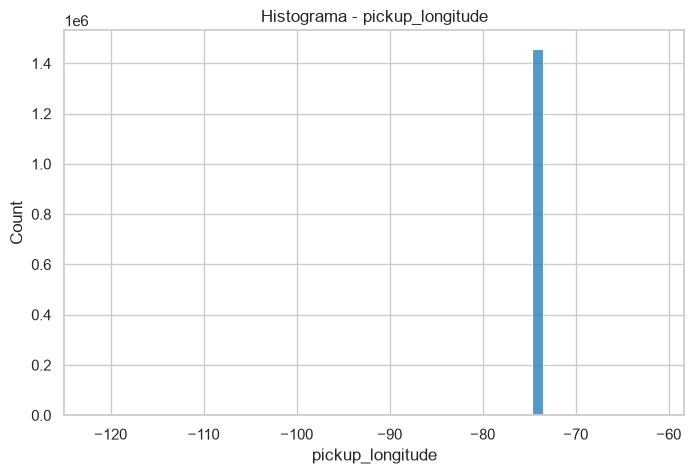

--- Estadísticos de pickup_latitude ---
| Estadístico       |         Valor |
|:------------------|--------------:|
| Mínimo            |    34.3597    |
| Máximo            |    51.8811    |
| Media             |    40.7509    |
| Desviación típica |     0.0328812 |
| Asimetría         |     5.48913   |
| Curtosis          | 12950.2       |
| Valores distintos | 45245         |




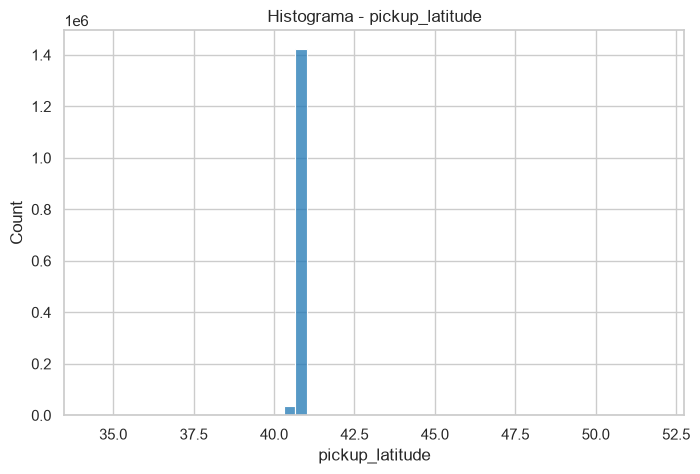

--- Estadísticos de dropoff_longitude ---
| Estadístico       |          Valor |
|:------------------|---------------:|
| Mínimo            |   -121.933     |
| Máximo            |    -61.3355    |
| Media             |    -73.9734    |
| Desviación típica |      0.0706433 |
| Asimetría         |   -425.332     |
| Curtosis          | 292526         |
| Valores distintos |  33821         |




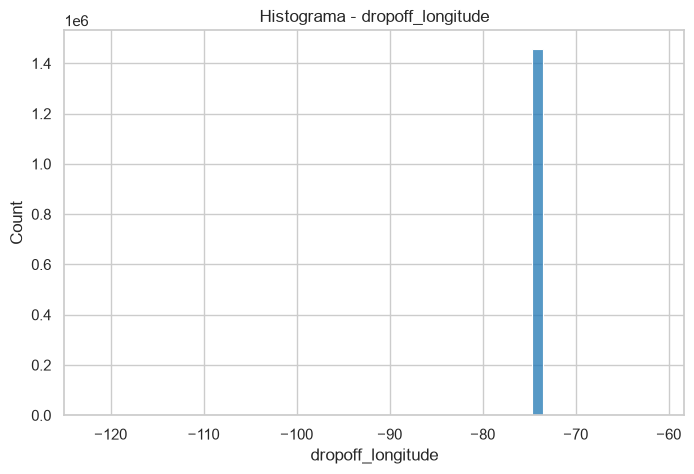

--- Estadísticos de dropoff_latitude ---
| Estadístico       |         Valor |
|:------------------|--------------:|
| Mínimo            |    32.1811    |
| Máximo            |    43.921     |
| Media             |    40.7518    |
| Desviación típica |     0.0358906 |
| Asimetría         |   -20.6712    |
| Curtosis          |  4259.54      |
| Valores distintos | 62519         |




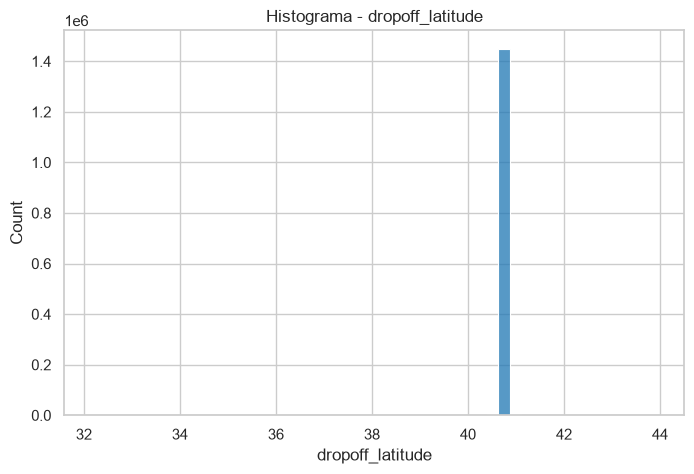

--- Estadísticos de trip_duration ---
| Estadístico       |            Valor |
|:------------------|-----------------:|
| Mínimo            |      1           |
| Máximo            |      3.52628e+06 |
| Media             |    959.492       |
| Desviación típica |   5237.43        |
| Asimetría         |    343.164       |
| Curtosis          | 192132           |
| Valores distintos |   7417           |




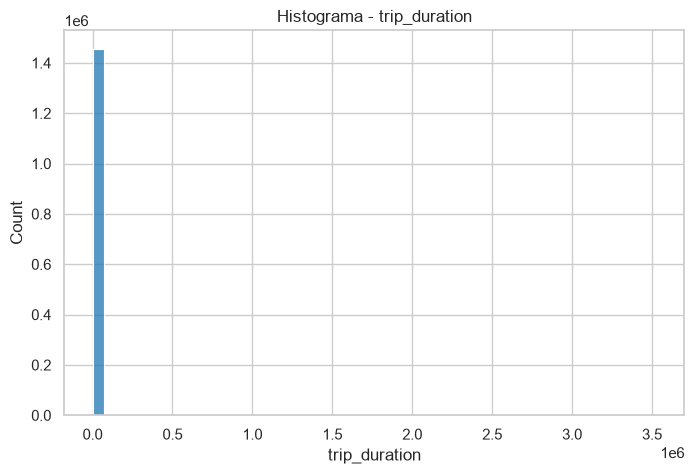

In [29]:
print("==========================================================")
print("2. ATRIBUTOS NUMÉRICOS CONTINUOS")
print("==========================================================\n")

for col in numeric_cols:
    stats = {
        'Estadístico': ['Mínimo', 'Máximo', 'Media', 'Desviación típica', 'Asimetría', 'Curtosis', 'Valores distintos'],
        'Valor': [
            df[col].min(), df[col].max(), df[col].mean(), 
            df[col].std(), df[col].skew(), df[col].kurtosis(), 
            df[col].nunique()
        ]
    }
    stats_df = pd.DataFrame(stats)
    
    print(f"--- Estadísticos de {col} ---")
    print(stats_df.to_markdown(index=False))
    print("\n")
    
    # --- Generación de Gráfica (Escala normal/lineal) ---
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], bins=50, kde=False, color="tab:blue")
    plt.title(f"Histograma - {col}")
    plt.show()

In [30]:
print("==========================================================")
print("3. ATRIBUTOS TEMPORALES (Rangos)")
print("==========================================================\n")

for col in temporal_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')
    print(f"--- Rango Temporal de {col} ---")
    print(f"Mínimo: {df[col].min()}")
    print(f"Máximo: {df[col].max()}\n")

3. ATRIBUTOS TEMPORALES (Rangos)

--- Rango Temporal de pickup_datetime ---
Mínimo: 2016-01-01 00:00:17
Máximo: 2016-06-30 23:59:39

--- Rango Temporal de dropoff_datetime ---
Mínimo: 2016-01-01 00:03:31
Máximo: 2016-07-01 23:02:03

